Practical NO.02(A)  
Name - Sakshi Vijaykumar Muthiyan     
Roll No. -      
Title - Predict the price of the Uber ride from a given pickup point to the agreed drop-off location. Perform following tasks: 
1. Pre-process the dataset. 2. Identify outliers. 3. Check the correlation. 4. Implement linear regression and ridge, Lasso regression models.5.Evaluate the models and compare their respective scores like R2, RMSE, etc. Dataset link: https://www.kaggle.com/datasets/yasserh/uber-fares-dataset 

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, mean_squared_error
import warnings
warnings.filterwarnings('ignore')
print("All required regression libraries imported successfully.")

All required regression libraries imported successfully.


In [4]:
# Using your verified folder path with raw string format to prevent unicode errors
path = r"C:\Users\muthi\OneDrive\Desktop\PRACTICAL EXAM\ML\uber.csv"
print("Loading Uber Fares dataset from local path...")
df = pd.read_csv(path)
print(f"Dataset loaded successfully! Initial Shape: {df.shape}")
df.head(3) # Space saving printout footprint

Loading Uber Fares dataset from local path...
Dataset loaded successfully! Initial Shape: (200000, 9)


,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1


In [5]:
# Drop columns that aren't numeric features for basic regression modeling
# Handling missing values
df = df.dropna()

# Haversine formula calculation to convert coordinates into spatial travel distance in kilometers
def haversine_distance(lon1, lat1, lon2, lat2):
    lon1, lat1, lon2, lat2 = map(np.radians, [lon1, lat1, lon2, lat2])
    dlon = lon2 - lon1
    dlat = lat2 - lat1
    a = np.sin(dlat/2.0)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2.0)**2
    c = 2.0 * np.arcsin(np.sqrt(a))
    km = 6367.0 * c
    return km

df['ride_distance_km'] = haversine_distance(
    df['pickup_longitude'], df['pickup_latitude'],
    df['dropoff_longitude'], df['dropoff_latitude']
)

print("Data cleaning and feature engineering complete.")
df[['fare_amount', 'ride_distance_km']].head(3)


Data cleaning and feature engineering complete.


,fare_amount,ride_distance_km
0,7.5,1.682266
1,7.7,2.456047
2,12.9,5.033215


In [6]:
print(f"Row count before outlier filtering: {len(df)}")
# Filtering realistic logical constraints to remove standard coordinate/fare outliers
df = df[(df['fare_amount'] > 0) & (df['fare_amount'] < 200)]
df = df[(df['ride_distance_km'] > 0) & (df['ride_distance_km'] < 100)]
if 'passenger_count' in df.columns:
    df = df[(df['passenger_count'] > 0) & (df['passenger_count'] <= 6)]
print(f"Row count after outlier filtering: {len(df)}")

Row count before outlier filtering: 199999
Row count after outlier filtering: 193188


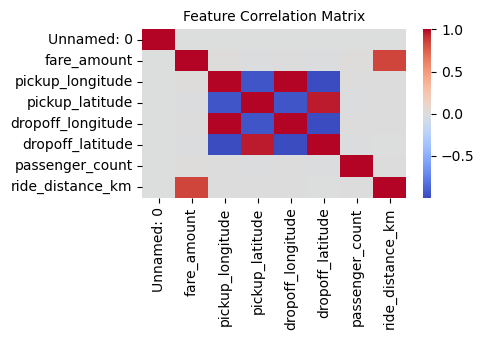

In [7]:
# Create a compact correlation matrix plot to check feature relationship scales
plt.figure(figsize=(5, 3.5))
# Isolating numerical metrics for mapping
numerical_cols = df.select_dtypes(include=[np.number]).columns
correlation_matrix = df[numerical_cols].corr()
sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm')
plt.title('Feature Correlation Matrix', fontsize=10)
plt.tight_layout()
plt.show()

In [8]:
# Select primary regression predictors
features = ['pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'ride_distance_km']
X = df[features]
y = df['fare_amount']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Data successfully split and normalized for regression training.")

Data successfully split and normalized for regression training.


In [9]:
# Instantiating required Linear, Ridge, and Lasso configurations
models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Lasso Regression': Lasso(alpha=0.1)
}
results = {}
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    predictions = model.predict(X_test_scaled) 
    r2 = r2_score(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    results[name] = {'R2 Score': r2, 'RMSE': rmse}
# Generate evaluation matrix dataframe
results_df = pd.DataFrame(results).T
print("=== SPPU Model Performance Comparison Matrix ===")
print(results_df)

=== SPPU Model Performance Comparison Matrix ===
                   R2 Score       RMSE
Linear Regression -1.980899  16.545204
Ridge Regression  -1.573202  15.372178
Lasso Regression   0.724590   5.029076


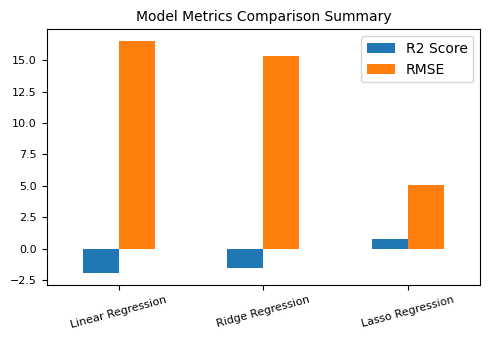

In [10]:
# Minimal display performance metrics chart to keep printing clean
results_df.plot(kind='bar', figsize=(5, 3.5))
plt.title('Model Metrics Comparison Summary', fontsize=10)
plt.xticks(rotation=15, fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()